# PROJETO FINAL - Análise de sazonalidade e demanda na indústria hoteleira

## 1. Contexto e objetivo do projeto

A sazonalidade da demanda é um desafio para a gestão hoteleira, pois as variações no volume de reservas ao longo do ano podem influenciar os preços das diárias, o planejamento das equipes e as estratégias de marketing.

Este projeto tem como objetivo analisar a sazonalidade das reservas na indústria hoteleira, identificando os períodos de maior e menor demanda e comparando os padrões entre o City Hotel e o Resort Hotel.

A análise também investiga a variação do preço médio das diárias (ADR) ao longo do ano e verifica, por meio de testes estatísticos, se existe associação entre o mês de chegada e o tipo de hotel e se o ADR médio é maior nos períodos classificados como de alta demanda.

Os resultados poderão apoiar decisões de precificação, planejamento operacional e ações de marketing. A análise considera as limitações da base de dados, especialmente a ausência de informações sobre a capacidade total de hospedagem.

In [38]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import ttest_ind
from scipy.stats import chi2_contingency

In [39]:
df = pd.read_csv('hotel_booking.csv')
print(df.info())
print(df.isnull().sum()[df.isnull().sum() > 0])
print('Total de duplicatas:', df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 36 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [40]:
colunas_sensiveis = ['name', 'email', 'phone-number', 'credit_card']

df = df.drop(columns=colunas_sensiveis)

print('Dimensões após a remoção:', df.shape)
print('Colunas restantes:')
print(df.columns.tolist())

Dimensões após a remoção: (119390, 32)
Colunas restantes:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']


In [41]:
ausentes = df.isnull().sum()
percentual_ausentes = (ausentes / len(df)) * 100

resumo_ausentes = pd.DataFrame({
    'Valores ausentes': ausentes,
    'Percentual (%)': percentual_ausentes
})

print(resumo_ausentes[resumo_ausentes['Valores ausentes'] > 0])

          Valores ausentes  Percentual (%)
children                 4        0.003350
country                488        0.408744
agent                16340       13.686238
company             112593       94.306893


In [42]:
df['children'] = df['children'].fillna(0)

print('Valores ausentes em children:', df['children'].isnull().sum())

Valores ausentes em children: 0


In [43]:
ordem_meses = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

df['arrival_date_month'] = pd.Categorical(
    df['arrival_date_month'],
    categories=ordem_meses,
    ordered=True
)

print(df['arrival_date_month'].cat.categories.tolist())

['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']


In [44]:
df_analise = df[df['adr'] >= 0].copy()

print("Estatísticas descritivas do ADR (sem valores negativos):")
print(df_analise['adr'].describe())

Estatísticas descritivas do ADR (sem valores negativos):
count    119389.000000
mean        101.832028
std          50.535032
min           0.000000
25%          69.290000
50%          94.590000
75%         126.000000
max        5400.000000
Name: adr, dtype: float64


### Conclusão da limpeza inicial

O conjunto de dados contém 119.390 registros e 36 colunas originais. Foram identificados 4 valores ausentes em `children`, 488 em `country`, 16.340 em `agent` e 112.593 em `company`. Não foram encontradas linhas duplicadas completas.

As colunas pessoais `name`, `email`, `phone-number` e `credit_card` foram removidas, reduzindo o conjunto para 32 colunas. Os 4 valores ausentes de `children` foram preenchidos com `0`, embora não seja possível confirmar essa informação na fonte original. Os valores ausentes de `country`, `agent` e `company` foram mantidos, pois não impedem a análise principal e podem representar informações não registradas sobre a reserva.

Sobre a organização dos meses, a coluna `arrival_date_month` foi definida como categórica ordenada, garantindo que os meses apareçam de janeiro a dezembro nos agrupamentos e gráficos, em vez de seguir a ordem alfabética.

In [45]:
df[['lead_time', 'adr', 'stays_in_weekend_nights',
    'stays_in_week_nights']].describe()

,lead_time,adr,stays_in_weekend_nights,stays_in_week_nights
count,119390.000000,119390.000000,119390.000000,119390.000000
mean,104.011416,101.831122,0.927599,2.500302
std,106.863097,50.535790,0.998613,1.908286
min,0.000000,-6.380000,0.000000,0.000000
25%,18.000000,69.290000,0.000000,1.000000
50%,69.000000,94.575000,1.000000,2.000000
75%,160.000000,126.000000,2.000000,3.000000
max,737.000000,5400.000000,19.000000,50.000000


### Conclusão da análise descritiva

O prazo médio entre a reserva e a chegada (`lead_time`) é de 104 dias, enquanto a mediana é de 69 dias, indicando que parte das reservas é realizada com bastante antecedência. A estadia apresenta médias de aproximadamente 0,93 noite nos fins de semana e 2,50 noites durante a semana.

A variável `adr` apresenta média de 101,83 e mediana de 94,58. Entretanto, o valor mínimo é negativo (-6,38) e o máximo chega a 5.400, indicando valores que precisam ser investigados antes da análise sazonal. Também serão verificados os máximos de 19 noites de fim de semana e 50 noites durante a semana.

In [46]:
print('ADR negativo:', (df['adr'] < 0).sum())
print('ADR igual a zero:', (df['adr'] == 0).sum())
print('ADR acima de 1000:', (df['adr'] > 1000).sum())

print(df[df['adr'] > 1000][
    ['hotel', 'is_canceled', 'adults', 'children', 'adr']
].head(10))

ADR negativo: 1
ADR igual a zero: 1959
ADR acima de 1000: 1
            hotel  is_canceled  adults  children     adr
48515  City Hotel            1       2       0.0  5400.0


In [47]:
print(
    df[(df['adr'] < 0) | (df['adr'] > 1000)][
        ['hotel', 'is_canceled', 'lead_time',
         'adults', 'children', 'stays_in_weekend_nights',
         'stays_in_week_nights', 'adr',
         'reservation_status', 'reservation_status_date']
    ]
)

              hotel  is_canceled  lead_time  adults  children  \
14969  Resort Hotel            0        195       2       0.0   
48515    City Hotel            1         35       2       0.0   

       stays_in_weekend_nights  stays_in_week_nights      adr  \
14969                        4                     6    -6.38   
48515                        0                     1  5400.00   

      reservation_status reservation_status_date  
14969          Check-Out              2017-03-15  
48515           Canceled              2016-02-19  


In [48]:
reservas_por_mes = (
    df['arrival_date_month']
    .value_counts()
    .reindex(ordem_meses)
)

print(reservas_por_mes)

arrival_date_month
January       5929
February      8068
March         9794
April        11089
May          11791
June         10939
July         12661
August       13877
September    10508
October      11160
November      6794
December      6780
Name: count, dtype: int64


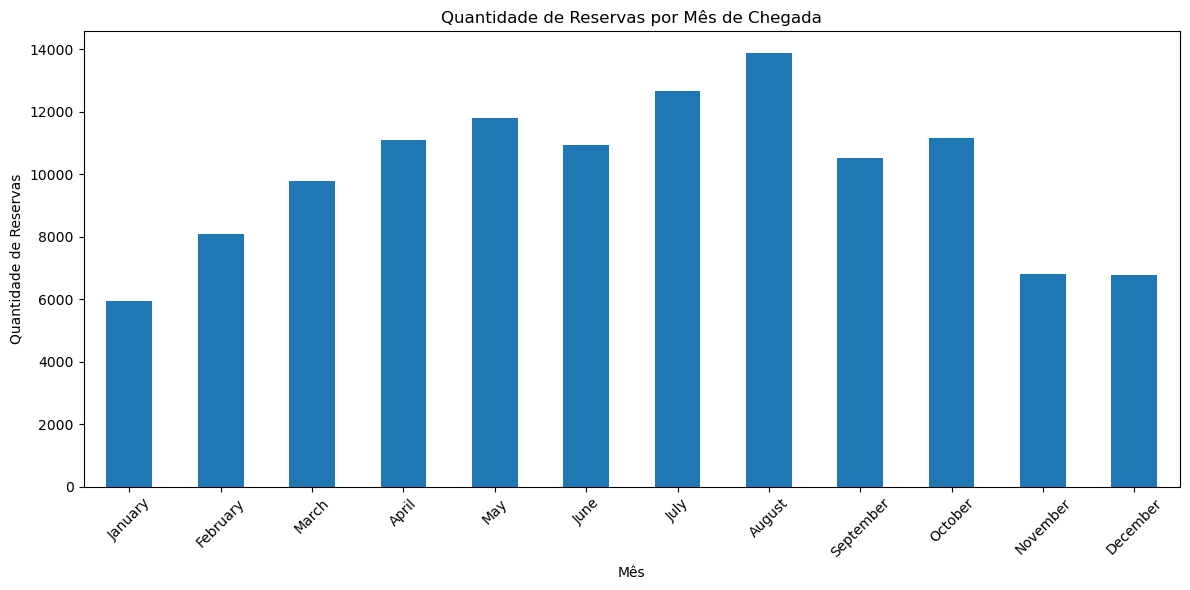

In [49]:
plt.figure(figsize=(12, 6))

reservas_por_mes.plot(kind='bar')

plt.title('Quantidade de Reservas por Mês de Chegada')
plt.xlabel('Mês')
plt.ylabel('Quantidade de Reservas')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

hotel               City Hotel  Resort Hotel
arrival_date_month                          
January                   3736          2193
February                  4965          3103
March                     6458          3336
April                     7480          3609
May                       8232          3559
June                      7894          3045
July                      8088          4573
August                    8983          4894
September                 7400          3108
October                   7605          3555
November                  4357          2437
December                  4132          2648


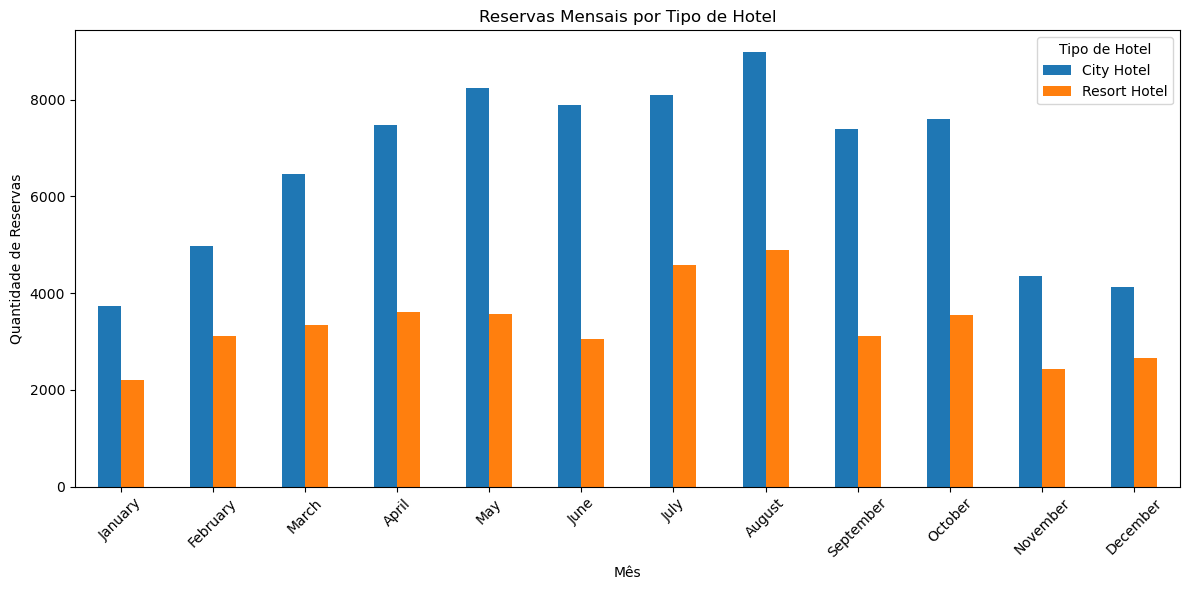

In [50]:
reservas_por_hotel = df.groupby(
    ['arrival_date_month', 'hotel'],
    observed=False
).size().unstack(fill_value=0)

print(reservas_por_hotel)

reservas_por_hotel.plot(kind='bar', figsize=(12, 6))

plt.title('Reservas Mensais por Tipo de Hotel')
plt.xlabel('Mês')
plt.ylabel('Quantidade de Reservas')
plt.xticks(rotation=45)
plt.legend(title='Tipo de Hotel')
plt.tight_layout()
plt.show()

arrival_date_year   2015  2016  2017
arrival_date_month                  
January                0  2248  3681
February               0  3891  4177
March                  0  4824  4970
April                  0  5428  5661
May                    0  5478  6313
June                   0  5292  5647
July                2776  4572  5313
August              3889  5063  4925
September           5114  5394     0
October             4957  6203     0
November            2340  4454     0
December            2920  3860     0


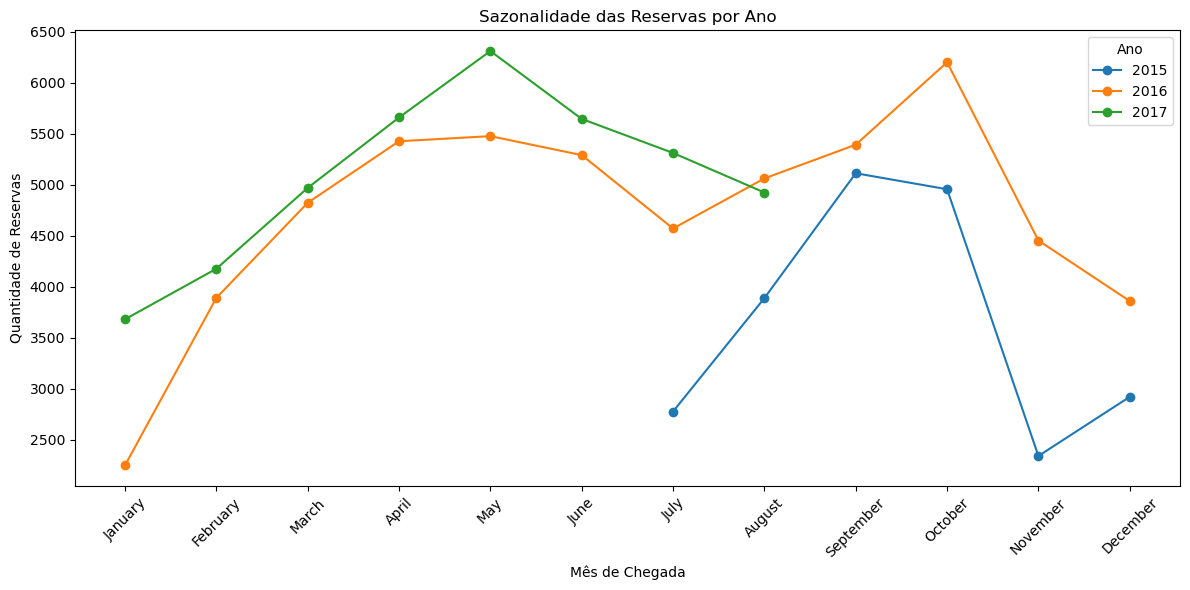

In [51]:
reservas_por_ano = df.pivot_table(
    index='arrival_date_month',
    columns='arrival_date_year',
    values='hotel',
    aggfunc='count',
    observed=False
)

print(reservas_por_ano)

reservas_por_ano_grafico = reservas_por_ano.replace(0, float('nan'))

reservas_por_ano_grafico.plot(
    kind='line',
    marker='o',
    figsize=(12, 6)
)

plt.title('Sazonalidade das Reservas por Ano')
plt.xlabel('Mês de Chegada')
plt.ylabel('Quantidade de Reservas')
plt.xticks(range(12), ordem_meses, rotation=45)
plt.legend(title='Ano')
plt.tight_layout()
plt.show()

### Análise gráfica da demanda

A análise mensal identificou agosto como o mês de maior demanda, com **13.877 reservas**, e janeiro como o de menor volume, com **5.929 reservas**. O City Hotel apresentou mais reservas que o Resort Hotel em todos os meses, e ambos atingiram seu pico em agosto, com 8.983 e 4.894 reservas, respectivamente.

A comparação anual mostrou que 2015 possui registros de julho a dezembro e 2017 de janeiro a agosto. Portanto, os meses sem registros nesses anos foram tratados como dados ausentes no gráfico, evitando interpretar períodos sem cobertura como meses sem demanda.

Os resultados indicam um padrão sazonal nos volumes de reservas, com destaque para julho e agosto. Essa análise considera a quantidade de reservas registradas, não a taxa real de ocupação dos hotéis.

arrival_date_month
January       70.361241
February      73.582276
March         80.679646
April        100.380790
May          108.695516
June         116.672192
July         126.788013
August       140.111523
September    105.049657
October       87.908879
November      73.794962
December      81.076776
Name: adr, dtype: float64


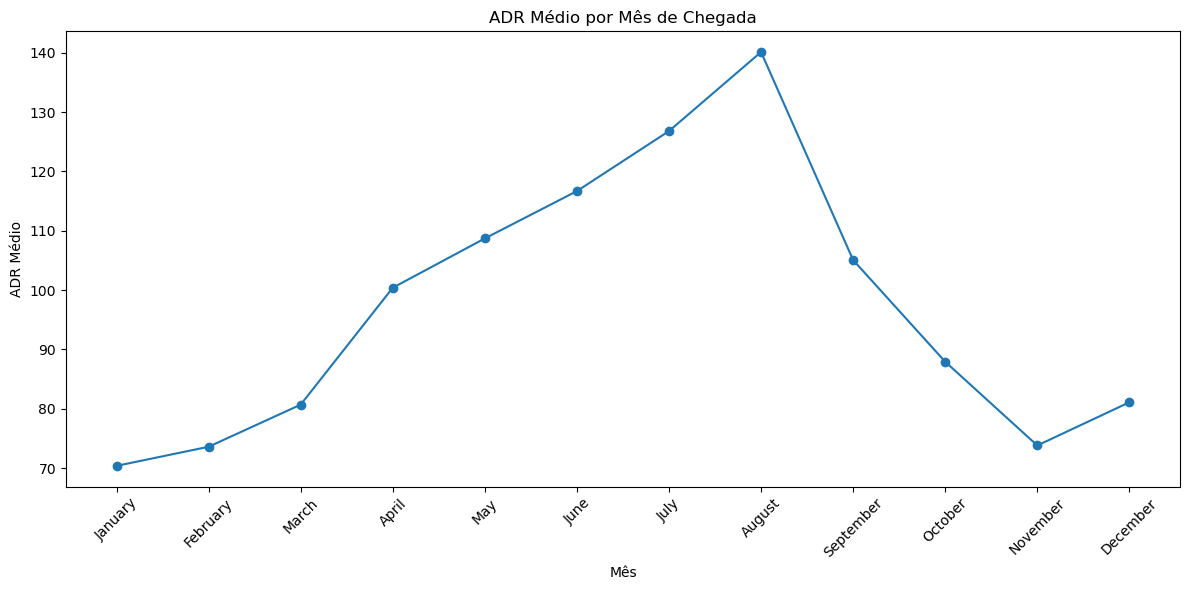

In [52]:
adr_por_mes = df.groupby(
    'arrival_date_month',
    observed=False
)['adr'].mean()

print(adr_por_mes)

adr_por_mes.plot(
    kind='line',
    marker='o',
    figsize=(12, 6)
)

plt.title('ADR Médio por Mês de Chegada')
plt.xlabel('Mês')
plt.ylabel('ADR Médio')
plt.xticks(range(12), ordem_meses, rotation=45)
plt.tight_layout()
plt.show()

hotel               City Hotel  Resort Hotel
arrival_date_month                          
January              82.628986     49.461883
February             85.088278     55.171930
March                92.643116     57.520147
April               111.251838     77.849496
May                 121.638560     78.758134
June                119.074341    110.444749
July                110.734292    155.181299
August              114.680455    186.790574
September           110.004661     93.252030
October              99.974498     62.097617
November             88.069601     48.273993
December             88.826307     68.984230


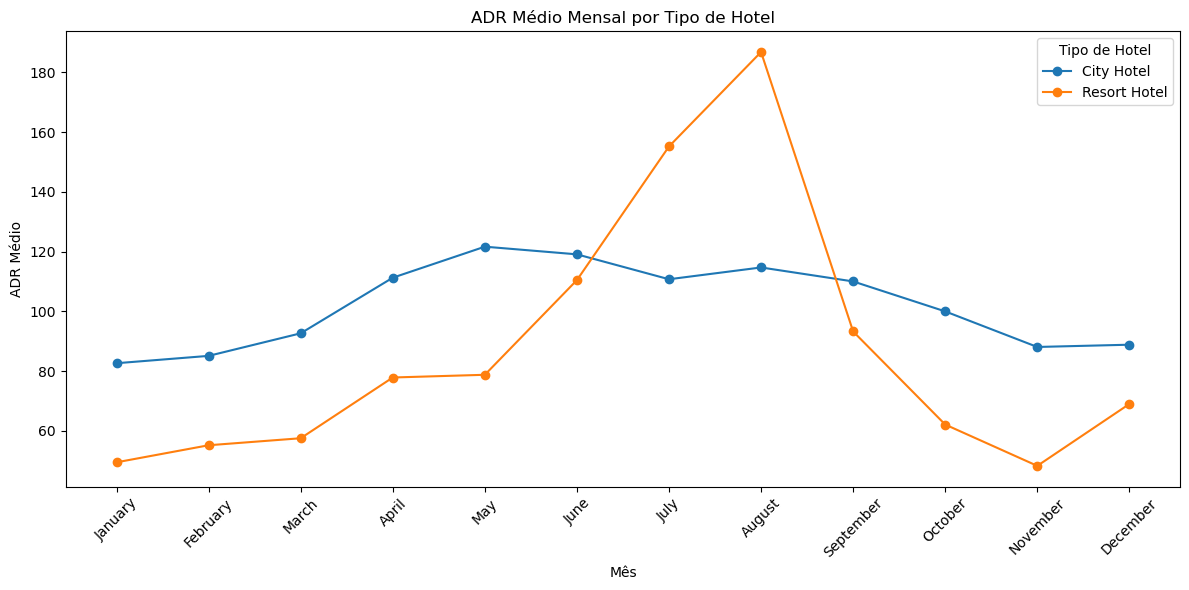

In [53]:
adr_por_hotel = df.pivot_table(
    index='arrival_date_month',
    columns='hotel',
    values='adr',
    aggfunc='mean',
    observed=False
)

print(adr_por_hotel)

adr_por_hotel.plot(
    kind='line',
    marker='o',
    figsize=(12, 6)
)

plt.title('ADR Médio Mensal por Tipo de Hotel')
plt.xlabel('Mês')
plt.ylabel('ADR Médio')
plt.xticks(range(12), ordem_meses, rotation=45)
plt.legend(title='Tipo de Hotel')
plt.tight_layout()
plt.show()

### Sazonalidade do ADR

O ADR médio aumenta de 70,36 em janeiro para 140,11 em agosto, recuando nos meses seguintes. A análise por tipo de hotel mostra comportamentos distintos: no City Hotel, o maior ADR ocorre em maio (121,64), enquanto no Resort Hotel o pico acontece em agosto (186,79).

O Resort Hotel apresenta ADR superior ao City Hotel entre junho e setembro, com a maior diferença em agosto. Esse resultado sugere maior variação sazonal das diárias no Resort Hotel e indica que os períodos de maior demanda podem estar associados a preços médios mais elevados.

Antes do teste de hipótese, será preciso definir os períodos de alta e baixa demanda e avaliar o impacto dos valores extremos de ADR.

In [54]:
resumo_cancelamento = df.groupby('is_canceled').agg(
    quantidade_reservas=('hotel', 'count'),
    adr_medio=('adr', 'mean'),
    adr_mediano=('adr', 'median'),
    adr_minimo=('adr', 'min'),
    adr_maximo=('adr', 'max')
)

resumo_cancelamento.index = [
    'Não canceladas' if valor == 0 else 'Canceladas'
    for valor in resumo_cancelamento.index
]

print(resumo_cancelamento)

                quantidade_reservas   adr_medio  adr_mediano  adr_minimo  \
Não canceladas                75166   99.987693         92.5       -6.38   
Canceladas                    44224  104.964333         96.2        0.00   

                adr_maximo  
Não canceladas       510.0  
Canceladas          5400.0  


In [55]:
df_2016 = df[
    (df['arrival_date_year'] == 2016) &
    (df['is_canceled'] == 0)
]

demanda_2016 = (
    df_2016.groupby('arrival_date_month', observed=False)
    .size()
    .reindex(ordem_meses, fill_value=0)
)

print(demanda_2016)

arrival_date_month
January      1691
February     2554
March        3347
April        3367
May          3563
June         3196
July         3073
August       3238
September    3372
October      3689
November     2818
December     2462
dtype: int64


In [56]:
limite_demanda = demanda_2016.median()

meses_alta = demanda_2016[demanda_2016 > limite_demanda].index.tolist()
meses_baixa = demanda_2016[demanda_2016 <= limite_demanda].index.tolist()

print('Mediana mensal de reservas:', limite_demanda)
print('Meses de alta demanda:', meses_alta)
print('Meses de baixa demanda:', meses_baixa)

Mediana mensal de reservas: 3217.0
Meses de alta demanda: ['March', 'April', 'May', 'August', 'September', 'October']
Meses de baixa demanda: ['January', 'February', 'June', 'July', 'November', 'December']


Critério de Seleção (2016 e Reservas Efetivadas): O cálculo dos limiares de demanda baseia-se exclusivamente no ano de 2016 (por ser o único período completo na base) e em reservas não canceladas, retratando a ocupação real sem distorções sazonais.

Nota temporal: A aparente divergência com a análise gráfica geral — onde julho e agosto aparecem como picos — ocorre porque a visão geral engloba múltiplos anos e reservas canceladas, enquanto este critério restrito reflete estritamente o comportamento efetivo do ano fechado de 2016. Ambas as abordagens são válidas em seus respectivos escopos.

In [57]:
df_analise = df[df['is_canceled'] == 0].copy()

df_analise['temporada'] = df_analise['arrival_date_month'].apply(
    lambda mes: 'Alta demanda' if mes in meses_alta else 'Baixa demanda'
)

resumo_adr_temporada = df_analise.groupby('temporada').agg(
    quantidade_reservas=('adr', 'count'),
    adr_medio=('adr', 'mean'),
    adr_mediano=('adr', 'median'),
    adr_minimo=('adr', 'min'),
    adr_maximo=('adr', 'max')
)

print(resumo_adr_temporada)

               quantidade_reservas   adr_medio  adr_mediano  adr_minimo  \
temporada                                                                 
Alta demanda                 42268  104.469277         96.9       -6.38   
Baixa demanda                32898   94.229665         88.0        0.00   

               adr_maximo  
temporada                  
Alta demanda        510.0  
Baixa demanda       508.0  


In [58]:
adr_temporada_hotel = df_analise.pivot_table(
    index='temporada',
    columns='hotel',
    values='adr',
    aggfunc='mean'
)

print(adr_temporada_hotel)

hotel          City Hotel  Resort Hotel
temporada                              
Alta demanda   109.818431     95.319391
Baixa demanda  100.190594     85.494653


### Teste de hipótese — ADR em períodos de alta e baixa demanda

**Objetivo:** verificar se o ADR médio das reservas não canceladas é maior nos meses classificados como de alta demanda.

**Hipóteses estatísticas:**

- **H₀ (hipótese nula):** o ADR médio na alta demanda é igual ou inferior ao da baixa demanda.
- **H₁ (hipótese alternativa):** o ADR médio na alta demanda é superior ao da baixa demanda.

**Nível de significância:** 5% (\(\alpha = 0{,}05\)).

**Método:** teste t de Welch unilateral para comparar as médias de dois grupos independentes, sem assumir variâncias iguais.

A classificação dos meses em alta e baixa demanda foi definida com base na mediana mensal de reservas não canceladas em 2016. Para a comparação, serão utilizadas as reservas não canceladas de todos os anos disponíveis.

In [59]:
adr_alta = df_analise[
    df_analise['arrival_date_month'].isin(meses_alta)
]['adr']

adr_baixa = df_analise[
    df_analise['arrival_date_month'].isin(meses_baixa)
]['adr']

resultado = ttest_ind(
    adr_alta,
    adr_baixa,
    equal_var=False,
    alternative='greater'
)

print('ADR médio - alta demanda:', adr_alta.mean())
print('ADR médio - baixa demanda:', adr_baixa.mean())
print('Estatística t:', resultado.statistic)
print('P-valor:', resultado.pvalue)

if resultado.pvalue < 0.05:
    print('Rejeitamos H0: há evidências de ADR médio maior na alta demanda.')
else:
    print('Não rejeitamos H0: não há evidências suficientes de ADR médio maior na alta demanda.')

ADR médio - alta demanda: 104.46927723100218
ADR médio - baixa demanda: 94.2296650252295
Estatística t: 28.550965925818236
P-valor: 1.3760049542909234e-178
Rejeitamos H0: há evidências de ADR médio maior na alta demanda.


### Conclusão do teste de hipótese do ADR

O teste t de Welch unilateral apresentou uma estatística t de **28,55** e um p-valor de aproximadamente **1,38 × 10⁻¹⁷⁸**, inferior ao nível de significância de 5% (α = 0,05). Portanto, rejeitamos a hipótese nula (H₀).

Os resultados fornecem evidências estatísticas de que o ADR médio das reservas não canceladas é maior nos meses classificados como de alta demanda. Nesses períodos, o ADR médio foi de **104,47**, contra **94,23** nos meses de baixa demanda, uma diferença de aproximadamente **10,24**.

Esse resultado sugere uma associação entre os períodos de maior demanda e diárias médias mais elevadas. Entretanto, não demonstra que o aumento da demanda seja, por si só, a causa do aumento do ADR. Além disso, a análise inclui um valor negativo de ADR, que deverá ser considerado como uma limitação dos dados.

Do ponto de vista do negócio, os resultados podem apoiar estratégias de precificação sazonal, desde que sejam considerados outros fatores que influenciam as diárias e a demanda.

### Teste de hipótese — Distribuição das reservas por tipo de hotel

**Objetivo:** verificar se a distribuição mensal das reservas difere entre o City Hotel e o Resort Hotel.

**Hipóteses estatísticas:**

- **H₀:** a distribuição mensal das reservas é independente do tipo de hotel.
- **H₁:** existe associação entre o mês de chegada e o tipo de hotel.

**Nível de significância:** 5% (α = 0,05).

**Método:** teste qui-quadrado de independência, utilizando as quantidades de reservas por mês e tipo de hotel.

In [60]:
tabela_reservas = pd.crosstab(
    df['arrival_date_month'],
    df['hotel']
)

resultado_h1 = chi2_contingency(tabela_reservas)

print('Estatística qui-quadrado:', resultado_h1.statistic)
print('Graus de liberdade:', resultado_h1.dof)
print('P-valor:', resultado_h1.pvalue)

if resultado_h1.pvalue < 0.05:
    print('Rejeitamos H0: existe associação entre o mês de chegada e o tipo de hotel.')
else:
    print('Não rejeitamos H0: não há evidências suficientes de associação entre o mês de chegada e o tipo de hotel.')


Estatística qui-quadrado: 598.130622992931
Graus de liberdade: 11
P-valor: 3.5175313992493777e-121
Rejeitamos H0: existe associação entre o mês de chegada e o tipo de hotel.


### Conclusão do teste de hipótese da demanda por tipo de hotel

O teste qui-quadrado de independência apresentou uma estatística de 598,13, com 11 graus de liberdade e p-valor de aproximadamente 3,52 × 10⁻¹²¹. Como o p-valor é inferior ao nível de significância de 5% (α = 0,05), rejeitamos a hipótese nula (H₀).

O resultado indica uma associação estatisticamente significativa entre o mês de chegada e o tipo de hotel. A distribuição mensal das reservas não é igual entre o City Hotel e o Resort Hotel, o que reforça a existência de padrões sazonais distintos entre os dois tipos de hospedagem.

Essa diferença pode apoiar o planejamento operacional e as estratégias de precificação e marketing específicas para cada hotel. Entretanto, o teste identifica uma associação, não uma relação de causa e efeito.

## Conclusão Geral do Projeto

O objetivo deste projeto foi analisar a sazonalidade e a demanda na indústria hoteleira, identificando padrões mensais nas reservas e verificando a relação entre a demanda, o tipo de hotel e o preço médio das diárias (ADR).

A análise exploratória identificou **agosto como o mês de maior volume de reservas**, com 13.877 registros, enquanto janeiro apresentou o menor volume, com 5.929. O City Hotel registrou mais reservas do que o Resort Hotel em todos os meses analisados, e ambos apresentaram seu maior volume em agosto..

A análise do ADR mostrou variações ao longo do ano. A média geral foi de 70,36 em janeiro e atingiu 140,11 em agosto. Também foram observados comportamentos distintos entre os hotéis: o ADR do City Hotel atingiu seu maior valor em maio, enquanto o Resort Hotel apresentou seu pico em agosto.

Os testes estatísticos reforçaram essas observações:

- **Hipótese 1 — Distribuição das reservas por tipo de hotel:** o teste qui-quadrado apresentou p-valor inferior a 0,05, indicando associação estatisticamente significativa entre o mês de chegada e o tipo de hotel.
- **Hipótese 2 — ADR em períodos de alta e baixa demanda:** o teste t de Welch apresentou p-valor inferior a 0,05. O ADR médio foi de 104,47 nos meses classificados como de alta demanda e de 94,23 nos meses de baixa demanda. A verificação sem o registro de ADR negativo manteve praticamente os mesmos resultados.

Do ponto de vista do negócio, os resultados podem apoiar estratégias de precificação sazonal, planejamento de equipes e recursos operacionais e campanhas de marketing direcionadas aos períodos de menor demanda. As diferenças entre os hotéis também indicam que estratégias específicas para cada tipo de hospedagem podem ser mais adequadas do que uma abordagem única.

**Limitações:** a base apresenta cobertura incompleta de alguns anos, e a presença de valores atípicos de ADR exige cautela na interpretação. Além disso, não há informações suficientes sobre a capacidade total de quartos disponíveis para calcular diretamente a taxa real de ocupação. Por fim, as associações identificadas não demonstram causalidade.

Conclui-se que a análise identificou padrões sazonais relevantes na demanda e nos preços médios das diárias, fornecendo informações úteis para apoiar decisões de gestão hoteleira baseadas em dados.